<a href="https://colab.research.google.com/github/IsaacBarnes2008/Final_Project_MTECH/blob/main/Isaac_Barnes_Final_Python_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step One: Ingesting the Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df= pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


### Step Two: Cleaning the Dataset
using the `.info()` and `.describe()` method, we can see if we have any missing values or anything that stands out in the data.



In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 38.1+ KB


We can see that sleep disorder has some null values. Lets see what all the unique values are.

In [4]:
df['Sleep Disorder'].value_counts()

,count
Sleep Disorder,
Sleep Apnea,78
Insomnia,77


To make out analysis and visualization easier in the future, lets fill the null values with the string 'None'.

In [5]:
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('None')
df['Sleep Disorder'].value_counts()

,count
Sleep Disorder,
None,219
Sleep Apnea,78
Insomnia,77


In [6]:
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


### Step 3: Data Manipulation

First, I want to see what occupation, on average, gets the best sleep by comparing an aggregation of Sleep Quality and Duration.

In [7]:
df.groupby('Occupation').agg(
    Sleep_Duration= ('Sleep Duration', 'mean'),
    Sleep_Quality= ('Quality of Sleep', 'mean')
    ).sort_values(by= 'Sleep_Duration', ascending= False)

,Sleep_Duration,Sleep_Quality
Occupation,,
Engineer,7.987302,8.412698
Lawyer,7.410638,7.893617
Accountant,7.113514,7.891892
Nurse,7.063014,7.369863
Doctor,6.970423,6.647887
Manager,6.900000,7.000000
Software Engineer,6.750000,6.500000
Teacher,6.690000,6.975000
Salesperson,6.403125,6.000000


According to the data, Engineers get the best sleep, while Sales Reps get the worst amount and quality of sleep.

Next, I want to see if men or women sleep better on average, using a similar aggregation method.

In [8]:
df.groupby('Gender').agg(
    Sleep_Duration= ('Sleep Duration', 'mean'),
    Sleep_Quality= ('Quality of Sleep', 'mean')
    ).sort_values(by= 'Sleep_Duration', ascending= False)

,Sleep_Duration,Sleep_Quality
Gender,,
Female,7.229730,7.664865
Male,7.036508,6.968254


According to the data, Women, on average, sleep longer and better than Men.

Finnally, I want to focus on the youngest of the dataset. I will filter for individuals who are under the age of 30, and compare their sleep quality accross different jobs.

In [9]:
df_young = df[df['Age'] < 30]
df_young.groupby('Occupation')['Quality of Sleep'].mean().sort_values(ascending= False)

,Quality of Sleep
Occupation,
Doctor,6.333333
Teacher,6.000000
Nurse,5.000000
Software Engineer,5.000000
Sales Representative,4.000000


This filtering revealed something interesting. When looking at all ages, teachers were in the bottom half of sleep quality. When filtered to ages less than 30, they ranked 2nd highest in sleep quality, right behind doctors. This tells us that younger teachers tend to sleep better on average compared to other aged teachers.

### Step 4: Visualizations

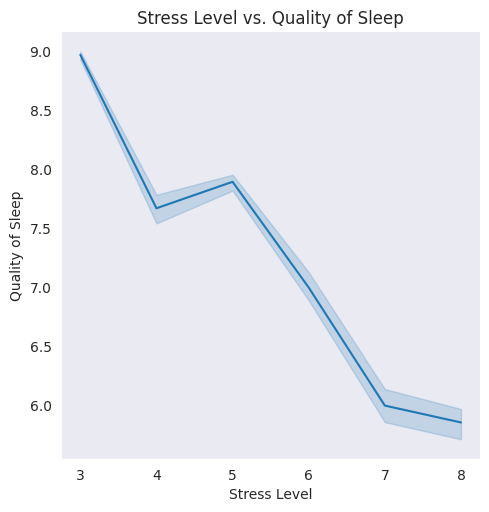

In [33]:
sns.set_style('dark')
sns.relplot(
    kind= 'line',
    x= 'Stress Level',
    y= 'Quality of Sleep',
    data= df
)
plt.title('Stress Level vs. Quality of Sleep')
plt.show()

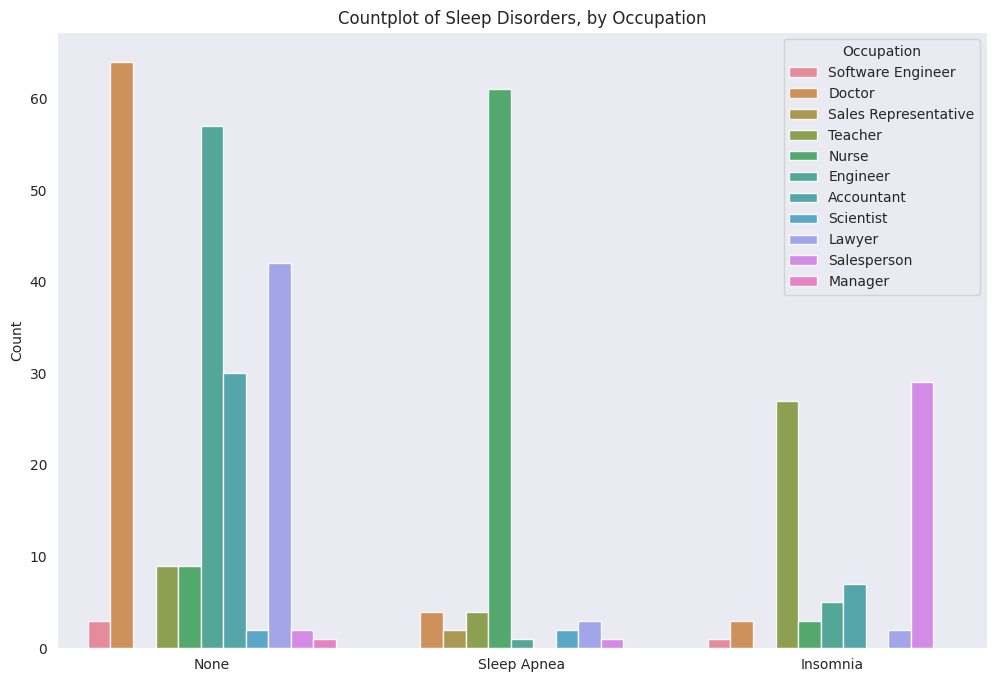

In [32]:
plt.figure(figsize= (12,8))
sns.countplot(
    x= 'Sleep Disorder',
    data= df,
    hue= 'Occupation',
    alpha= 0.9
)
plt.ylabel('Count')
plt.title('Countplot of Sleep Disorders, by Occupation')
plt.xlabel('')
plt.show()

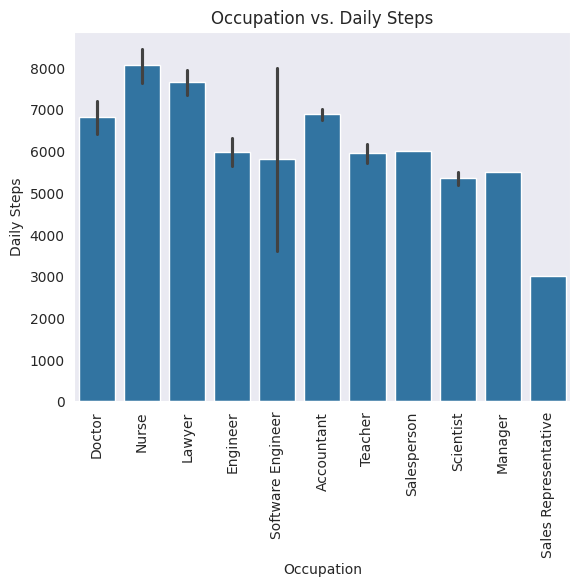

In [45]:
df = df.sort_values(by= 'Daily Steps', ascending= False)
sns.barplot(
    x= 'Occupation',
    y= 'Daily Steps',
    data = df,
)
plt.xticks(rotation= 90)
plt.title('Occupation vs. Daily Steps')
plt.show()

### Step 5: Statistical Analysis

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 374 entries, 2 to 4
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage: 40.9+ KB


In [53]:
df[['Physical Activity Level', 'Quality of Sleep', 'Sleep Duration', 'Stress Level',
    'Daily Steps', 'Heart Rate']].corr()

,Physical Activity Level,Quality of Sleep,Sleep Duration,Stress Level,Daily Steps,Heart Rate
Physical Activity Level,1.000000,0.192896,0.212360,-0.034134,0.772723,0.136971
Quality of Sleep,0.192896,1.000000,0.883213,-0.898752,0.016791,-0.659865
Sleep Duration,0.212360,0.883213,1.000000,-0.811023,-0.039533,-0.516455
Stress Level,-0.034134,-0.898752,-0.811023,1.000000,0.186829,0.670026
Daily Steps,0.772723,0.016791,-0.039533,0.186829,1.000000,-0.030309
Heart Rate,0.136971,-0.659865,-0.516455,0.670026,-0.030309,1.000000


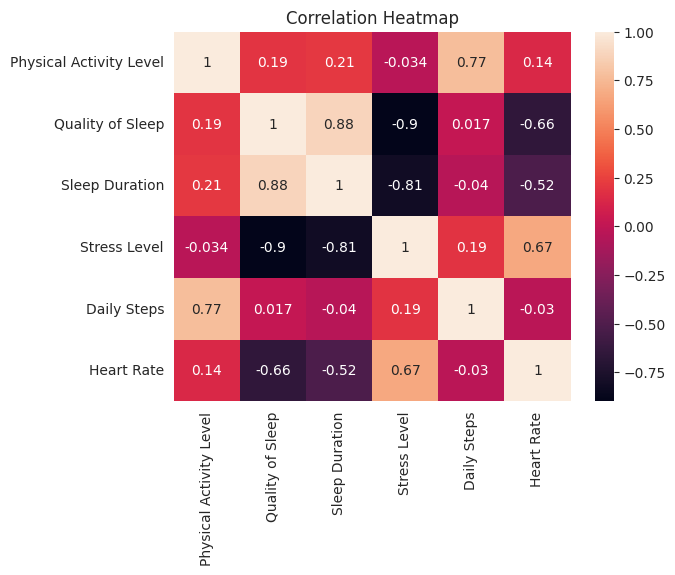

In [65]:

sns.heatmap(data= df[['Physical Activity Level', 'Quality of Sleep', 'Sleep Duration', 'Stress Level',
    'Daily Steps', 'Heart Rate']].corr(),
            annot= True)
plt.title('Correlation Heatmap')

plt.show()